In [79]:
import sys
sys.path.append("..")
import os
for root, dirs, files in os.walk("../data/real"):
    if files:
        print(root, "->", files)

        print(len(df), "images chargées ;", len(skipped), "illisibles")
print(df.groupby(["person", "letter"]).size().unstack(fill_value=0))

../data/real\malak\A -> ['01.jpeg', 'WhatsApp Image 2026-11-14 at 23.33.10.jpeg', 'WhatsApp Image 2026-11-14 at 23.33.11.jpeg', 'WhatsApp Image 2026-11-14 at 23.33.12.jpeg']
48 images chargées ; 0 illisibles
../data/real\malak\B -> ['02.jpeg', '33.jpg', 'WhatsApp Image 2026-11-14 at 22.56.28 (3).jpeg']
48 images chargées ; 0 illisibles
../data/real\malak\C -> ['03.jpeg', 'WhatsApp Image 2026-11-14 at 23.33.09.jpeg', 'WhatsApp Image 2026-11-14 at 23.33.13.jpeg']
48 images chargées ; 0 illisibles
../data/real\malak\D -> ['00.jpg']
48 images chargées ; 0 illisibles
../data/real\malak\E -> ['00.jpg']
48 images chargées ; 0 illisibles
../data/real\malak\F -> ['00.jpg']
48 images chargées ; 0 illisibles
../data/real\malak\H -> ['WhatsApp Image 2026-11-15 at 00.01.37.jpeg']
48 images chargées ; 0 illisibles
../data/real\malak\I -> ['WhatsApp Image 2026-11-15 at 00.01.42.jpeg']
48 images chargées ; 0 illisibles
../data/real\malak\K -> ['WhatsApp Image 2026-11-15 at 00.01.43.jpeg', 'WhatsApp Im

In [73]:
import os, json, glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from src.preprocess import preprocess_image

model = keras.models.load_model("../data/cnn_final.keras")

with open("../data/idx_to_letter.json") as f:
    idx_to_letter = {int(k): v for k, v in json.load(f).items()}
letter_to_idx = {v: k for k, v in idx_to_letter.items()}
letters = [idx_to_letter[i] for i in range(24)]

paths = []
for ext in ("jpg", "jpeg", "JPG", "JPEG", "png", "PNG"):
    paths += glob.glob(f"../data/real/*/*/*.{ext}")
paths = sorted(set(paths))

rows, X, skipped = [], [], []
for path in paths:
    parts = path.replace("\\", "/").split("/")
    person, letter = parts[-3], parts[-2].upper()
    if letter not in letter_to_idx:
        continue
    img = cv2.imread(path)
    if img is None:
        skipped.append(path)
        continue
    X.append(preprocess_image(img))
    rows.append({"person": person, "letter": letter,
                 "y": letter_to_idx[letter], "path": path})

X = np.array(X)
df = pd.DataFrame(rows)
print(len(df), "images chargées ;", len(skipped), "illisibles")
print(skipped)
print(df.groupby(["person", "letter"]).size().unstack(fill_value=0))

48 images chargées ; 0 illisibles
[]
letter  A  B  C  D  E  F  G  H  I  K  ...  P  Q  R  S  T  U  V  W  X  Y
person                                ...                              
malak   4  3  3  1  1  1  0  1  1  2  ...  1  1  1  0  1  2  1  1  0  1
sara    0  0  0  0  0  0  1  1  1  1  ...  1  1  1  1  1  1  1  1  1  1

[2 rows x 24 columns]


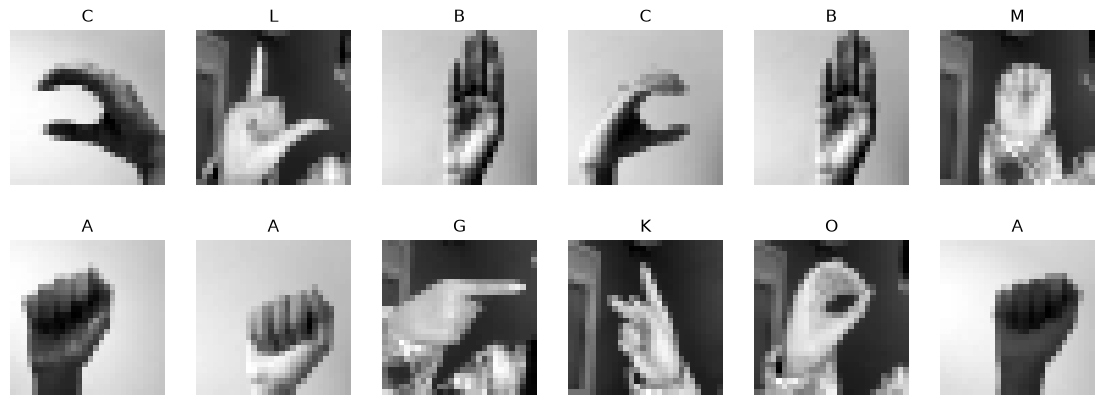

In [66]:
n_show = min(12, len(X))
idxs = np.random.default_rng(0).choice(len(X), n_show, replace=False)

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax in axes.ravel():
    ax.axis("off")
for ax, i in zip(axes.ravel(), idxs):
    ax.imshow(X[i].squeeze(), cmap="gray")
    ax.set_title(df.loc[i, "letter"])
plt.show()

In [75]:
proba = model.predict(X, verbose=0)
df["pred"] = proba.argmax(axis=1)
df["conf"] = proba.max(axis=1)
df["ok"] = df["pred"] == df["y"]

print(f"Accuracy sur photos réelles : {df['ok'].mean():.3f}")
print(f"F1 macro : {f1_score(df['y'], df['pred'], average='macro'):.3f}")

print("\nAccuracy par personne :")
print(df.groupby("person")["ok"].mean().round(3))

print("\nAccuracy par lettre (les plus faibles) :")
print(df.assign(letter=df["letter"]).groupby("letter")["ok"].mean().sort_values().head(8).round(3))

Accuracy sur photos réelles : 0.458
F1 macro : 0.335

Accuracy par personne :
person
malak    0.600
sara     0.222
Name: ok, dtype: float64

Accuracy par lettre (les plus faibles) :
letter
C    0.0
G    0.0
F    0.0
E    0.0
H    0.0
M    0.0
L    0.0
I    0.0
Name: ok, dtype: float64


In [76]:
print(df.groupby("ok")["conf"].describe().round(3))

       count   mean    std    min    25%    50%    75%    max
ok                                                           
False   26.0  0.657  0.239  0.287  0.497  0.556  0.923  0.996
True    22.0  0.889  0.163  0.535  0.883  0.975  0.995  1.000


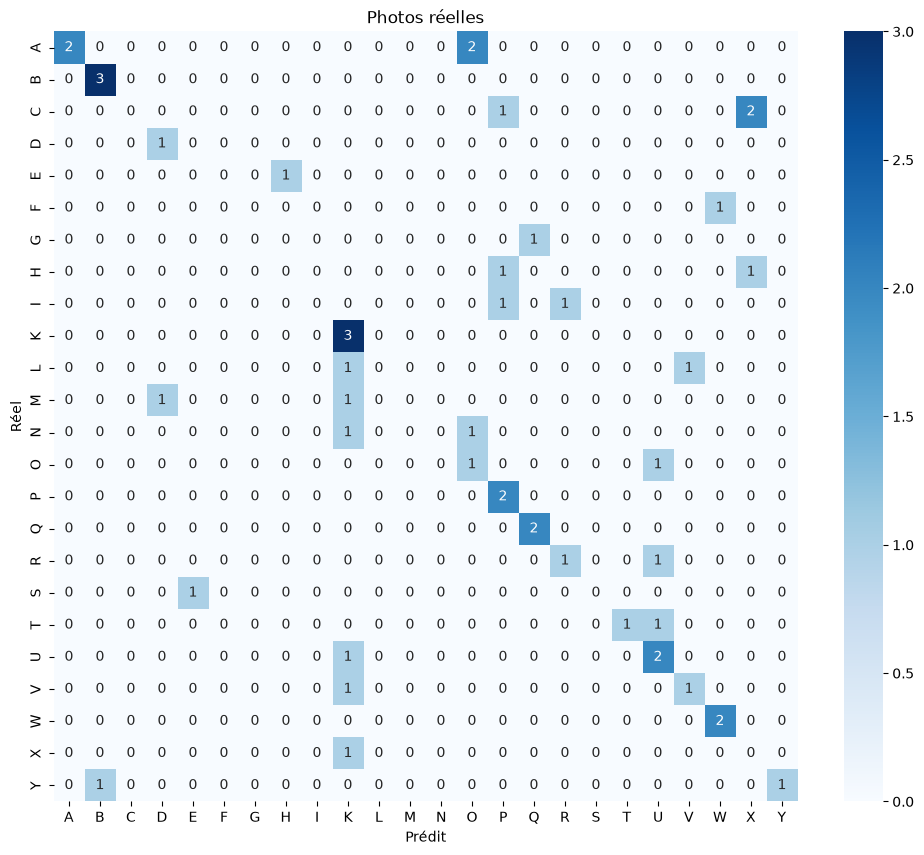

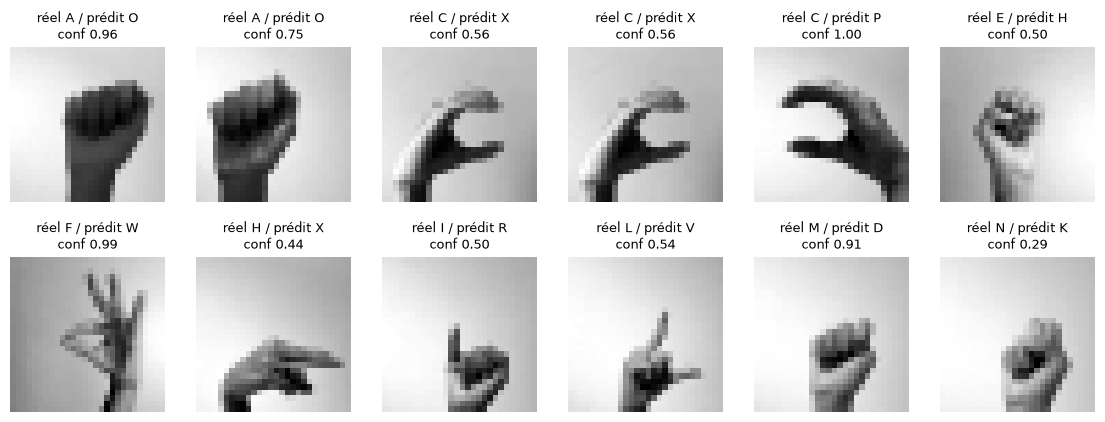

In [77]:
cm = confusion_matrix(df["y"], df["pred"], labels=range(24))
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=letters, yticklabels=letters)
plt.xlabel("Prédit"); plt.ylabel("Réel"); plt.title("Photos réelles")
plt.show()

wrong = df[~df["ok"]].head(12)
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, (i, r) in zip(axes.ravel(), wrong.iterrows()):
    ax.imshow(X[i].squeeze(), cmap="gray")
    ax.set_title(f"réel {idx_to_letter[r['y']]} / prédit {idx_to_letter[r['pred']]}\nconf {r['conf']:.2f}", fontsize=9)
    ax.axis("off")
plt.show()

In [70]:
real_results = {
    "n_images": int(len(df)),
    "n_persons": int(df["person"].nunique()),
    "accuracy": float(df["ok"].mean()),
    "f1_macro": float(f1_score(df["y"], df["pred"], average="macro")),
    "accuracy_by_person": df.groupby("person")["ok"].mean().round(4).to_dict(),
}
with open("../docs/real_results.json", "w") as f:
    json.dump(real_results, f, indent=2)

In [78]:
def center_crop_zoom(img, zoom=0.7):
    h, w = img.shape[:2]
    s = int(min(h, w) * zoom)
    y0, x0 = (h - s) // 2, (w - s) // 2
    return img[y0:y0 + s, x0:x0 + s]

def prep_equalize(img):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    g = cv2.equalizeHist(g)
    return preprocess_image(cv2.cvtColor(g, cv2.COLOR_GRAY2BGR))

variants = {
    "normal": preprocess_image,
    "flip horizontal": lambda im: preprocess_image(cv2.flip(im, 1)),
    "zoom 70 %": lambda im: preprocess_image(center_crop_zoom(im, 0.7)),
    "zoom 50 %": lambda im: preprocess_image(center_crop_zoom(im, 0.5)),
    "égalisation": prep_equalize,
    "flip + zoom 70 %": lambda im: preprocess_image(center_crop_zoom(cv2.flip(im, 1), 0.7)),
}

imgs = [cv2.imread(p) for p in df["path"]]
for name, fn in variants.items():
    Xv = np.array([fn(im) for im in imgs])
    pred = model.predict(Xv, verbose=0).argmax(1)
    print(f"{name:20s} accuracy = {(pred == df['y'].values).mean():.3f}")
    

normal               accuracy = 0.458
flip horizontal      accuracy = 0.229
zoom 70 %            accuracy = 0.438
zoom 50 %            accuracy = 0.229
égalisation          accuracy = 0.458
flip + zoom 70 %     accuracy = 0.229
